# EcoBuild: Figures and Tables for the Research Paper
**Notebook for the paper: Machine Learning / Production Lead**

**Research question:** To what extent does testing on whole held-out designs, instead of a random 80/20 split, change the heating and cooling load error of a Gradient Boosting model on the UCI Energy Efficiency dataset, measured by MAE and RMSE?

**Hypothesis:** error on whole held-out designs will be higher than error under a random split. **Null hypothesis:** there is no difference.

**The story in seven figures.** What the data looks like (Figures 1 to 3), why a random split can mislead (Figure 1b), how much the measured error changes when whole designs are held out (Figures 4 and 5), how good the predictions are on new designs (Figure 6), and what drives them (Figure 7).

**What this notebook produces**
1. Table 1 and Figures 1 to 3: the data and exploratory analysis (paper Section 3).
2. The main experiment: the random-vs-whole-design comparison **repeated over 100 different splits**, for three models, so the result comes with a spread and a significance test and not just one number (Section 5).
3. Figures 4 and 5 for the results, Figure 6 for predicted vs actual, Figure 7 for SHAP explanations (Sections 5 and 6).
4. A short list of the numbers the paper quotes, printed at the end.

All figures are saved at IEEE sizes (3.5 in for one column, 7.16 in for two columns) as PNG and PDF, and all tables as CSV, then zipped. Model tuning is not repeated here: it is in the Update 3 notebook (Sections 7 and 8).

*Running time: about 10 minutes.*

## 1. Setup

In [1]:
import os, sys, json, shutil, subprocess, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from joblib import Parallel, delayed

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "-q"])
    import shap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
N_REPEATS = 100
FIG_DIR, TAB_DIR = "paper_figures", "paper_tables"
for d in (FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

# IEEE sizes (inches) and a print-friendly style: white background, text in neutral ink, quiet grid
ONE_COL, TWO_COL = 3.5, 7.16
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"       # validated categorical colors, in fixed order
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.size": 7.5, "axes.labelsize": 7.5, "axes.titlesize": 8,
    "axes.titleweight": "normal", "axes.titlelocation": "left", "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "legend.frameon": False, "figure.dpi": 110,
})

def save(fig, name):
    """Save a figure as PNG (300 dpi) and PDF (vector) for Overleaf."""
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")

def save_table(tbl, name):
    tbl.to_csv(f"{TAB_DIR}/{name}.csv", index=True)

print("Setup complete. scikit-learn", __import__("sklearn").__version__, "| shap", shap.__version__)

Setup complete. scikit-learn 1.9.1 | shap 0.54.1


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the data
UCI Energy Efficiency (`ENB2012_data.xlsx`). *In Colab, run the cell and pick the file when asked. Locally, keep the file next to this notebook.*

In [2]:
FILE = "ENB2012_data.xlsx"
if not os.path.exists(FILE):
    from google.colab import files
    files.upload()

raw = pd.read_excel(FILE)
df = raw.rename(columns={
    "X1": "Relative_Compactness", "X2": "Surface_Area", "X3": "Wall_Area", "X4": "Roof_Area",
    "X5": "Overall_Height", "X6": "Orientation", "X7": "Glazing_Area",
    "X8": "Glazing_Area_Distribution", "Y1": "Heating_Load", "Y2": "Cooling_Load",
})
FEATURES = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height",
            "Orientation", "Glazing_Area", "Glazing_Area_Distribution"]
TARGETS = ["Heating_Load", "Cooling_Load"]
SHAPE_COLS = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height"]
DESIGN_COLS = [c for c in FEATURES if c != "Orientation"]
LABEL = {"Relative_Compactness": "Relative compactness", "Surface_Area": "Surface area", "Wall_Area": "Wall area",
         "Roof_Area": "Roof area", "Overall_Height": "Overall height", "Orientation": "Orientation",
         "Glazing_Area": "Glazing area", "Glazing_Area_Distribution": "Glazing distribution",
         "Heating_Load": "Heating load", "Cooling_Load": "Cooling load"}

df["design_id"] = df.groupby(DESIGN_COLS).ngroup()
df["form_id"] = df.groupby(SHAPE_COLS).ngroup()
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()),
      "| designs:", df.design_id.nunique(), "| building forms:", df.form_id.nunique())

Shape: (768, 12) | missing values: 0 | designs: 192 | building forms: 12


## 3. Data: Table 1 and exploratory analysis (paper Section 3)

In [3]:
spread = df.groupby("design_id")[TARGETS].agg(lambda s: s.max() - s.min())
t1 = pd.DataFrame({
    "Value": [
        len(df), df.design_id.nunique(), df.form_id.nunique(),
        ", ".join(str(h) for h in sorted(df.Overall_Height.unique())),
        ", ".join(str(int(o)) for o in sorted(df.Orientation.unique())),
        ", ".join(f"{g:g}" for g in sorted(df.Glazing_Area.unique())),
        int(df.isna().sum().sum()), int(df.duplicated().sum()),
        f"{df.Heating_Load.min():.1f} to {df.Heating_Load.max():.1f}  (mean {df.Heating_Load.mean():.1f}, SD {df.Heating_Load.std():.1f})",
        f"{df.Cooling_Load.min():.1f} to {df.Cooling_Load.max():.1f}  (mean {df.Cooling_Load.mean():.1f}, SD {df.Cooling_Load.std():.1f})",
        f"{spread.Heating_Load.mean():.2f} (heating), {spread.Cooling_Load.mean():.2f} (cooling)",
    ]},
    index=["Rows", "Distinct designs (all inputs except orientation)", "Building forms",
           "Overall height values (m)", "Orientation codes", "Glazing area values (share of floor area)",
           "Missing values", "Duplicate rows", "Heating load, kWh/m2", "Cooling load, kWh/m2",
           "Mean gap between a design's four orientations, kWh/m2"])
display(t1); save_table(t1, "table1_dataset_summary")

,Value
Rows,768
Distinct designs (all inputs except orientation),192
Building forms,12
Overall height values (m),"3.5, 7.0"
Orientation codes,"2, 3, 4, 5"
Glazing area values (share of floor area),"0, 0.1, 0.25, 0.4"
Missing values,0
Duplicate rows,0
"Heating load, kWh/m2","6.0 to 43.1 (mean 22.3, SD 10.1)"
"Cooling load, kWh/m2","10.9 to 48.0 (mean 24.6, SD 9.5)"


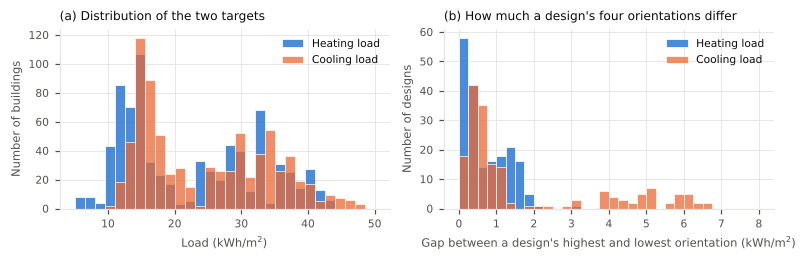

In [4]:
# Figure 1: (a) the two targets, (b) how little the four orientations of one design differ
fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 2.4))
ax = axes[0]
bins = np.linspace(5, 50, 31)
ax.hist(df.Heating_Load, bins=bins, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.6, label="Heating load")
ax.hist(df.Cooling_Load, bins=bins, color=ORANGE, alpha=0.75, edgecolor="white", linewidth=0.6, label="Cooling load")
ax.set_xlabel("Load (kWh/m$^2$)"); ax.set_ylabel("Number of buildings"); ax.legend()
ax.set_title("(a) Distribution of the two targets")
ax = axes[1]
bins = np.linspace(0, 8, 33)
ax.hist(spread.Heating_Load, bins=bins, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.6, label="Heating load")
ax.hist(spread.Cooling_Load, bins=bins, color=ORANGE, alpha=0.75, edgecolor="white", linewidth=0.6, label="Cooling load")
ax.set_xlabel("Gap between a design's highest and lowest orientation (kWh/m$^2$)")
ax.set_ylabel("Number of designs"); ax.legend()
ax.set_title("(b) How much a design's four orientations differ")
fig.tight_layout(); save(fig, "fig1_targets_and_orientation_gap"); plt.show()

**What this shows.** Heating loads run from 6 to 43 kWh/m² and cooling loads from 11 to 48, with two clusters (a low group and a high group). Panel (b) matters for everything that follows: the four orientations of one design differ by only 0.70 kWh/m² on average for heating and 2.34 for cooling, small next to the spread of the loads themselves (SD about 10). Each design is, in effect, four near-copies of one building.

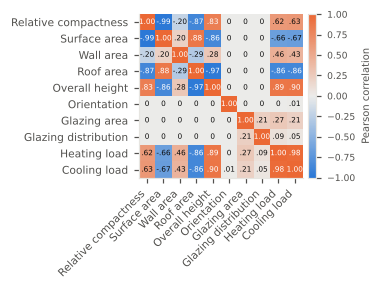

,Heating_Load,Cooling_Load
Relative_Compactness,0.62,0.63
Surface_Area,-0.66,-0.67
Wall_Area,0.46,0.43
Roof_Area,-0.86,-0.86
Overall_Height,0.89,0.90
Orientation,-0.00,0.01
Glazing_Area,0.27,0.21
Glazing_Area_Distribution,0.09,0.05
Heating_Load,1.00,0.98
Cooling_Load,0.98,1.00


In [5]:
# Figure 2: correlation of each input with the others and with the two loads
corr = df[FEATURES + TARGETS].corr()
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#ececea", ORANGE])
fig, ax = plt.subplots(figsize=(ONE_COL, 3.3))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
names = [LABEL[c] for c in corr.columns]
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        v = corr.values[i, j]
        lab = f"{v:.2f}"
        if lab in ("0.00", "-0.00"):
            lab = "0"
        elif lab != "1.00":
            lab = lab.replace("0.", ".")
        ax.text(j, i, lab, ha="center", va="center", fontsize=4.8,
                color="white" if abs(v) > 0.75 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("Pearson correlation", fontsize=6.5); cb.ax.tick_params(labelsize=6)
fig.tight_layout(); save(fig, "fig2_correlation_heatmap"); plt.show()
display(corr[TARGETS].round(2))
save_table(corr.round(3), "table_correlations")

**What this shows.** Overall height (r = 0.89 and 0.90) and roof area (r = -0.86) have the strongest links to both loads, and orientation has almost none (r = 0.00 and 0.01). Compactness, surface area, roof area and height are strongly related to one another (for example r = -0.99 for compactness and surface area), so they carry overlapping information.

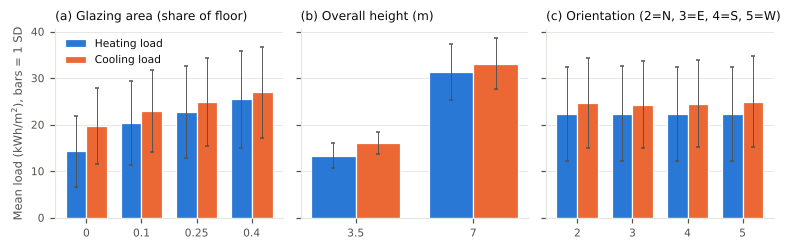

In [6]:
# Figure 3: average load by the three inputs that vary most in the story: glazing, height, orientation
fig, axes = plt.subplots(1, 3, figsize=(TWO_COL, 2.3), sharey=True)
for ax, feat, title in zip(axes, ["Glazing_Area", "Overall_Height", "Orientation"],
                           ["(a) Glazing area (share of floor)", "(b) Overall height (m)", "(c) Orientation (2=N, 3=E, 4=S, 5=W)"]):
    g = df.groupby(feat)[TARGETS].agg(["mean", "std"])
    x = np.arange(len(g)); w = 0.38
    for k, (t, color) in enumerate(zip(TARGETS, [BLUE, ORANGE])):
        ax.bar(x + (k - 0.5) * w, g[(t, "mean")], w, yerr=g[(t, "std")], color=color, edgecolor="white", linewidth=0.8,
               error_kw=dict(ecolor=INK_2, elinewidth=0.6, capsize=1.5), label=LABEL[t])
    ax.set_xticks(x); ax.set_xticklabels([f"{v:g}" for v in g.index]); ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Mean load (kWh/m$^2$), bars = 1 SD"); axes[0].legend(loc="upper left")
fig.tight_layout(); save(fig, "fig3_load_by_glazing_height_orientation"); plt.show()

**What this shows.** Loads rise steadily with glazing area, and two-story buildings (7 m) use far more energy than one-story buildings (3.5 m). Orientation barely moves the average load. This is why the four orientations of a design look alike, and why a random split lets the model peek at a test building through its twins.

## 4. The model pipeline (paper Section 4)
Same feature engineering and pipeline as the app. Gradient Boosting uses the prototype's tuned settings, as in Update 3, so the numbers match that notebook. Linear Regression is the baseline model and Random Forest the middle model.

In [7]:
NUM = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height",
       "Glazing_Area", "Wall_to_Roof_Ratio", "Envelope_per_Height", "Glazing_x_Height", "Is_Two_Story"]
CAT = ["Orientation", "Glazing_Area_Distribution"]

def engineer_features(data):
    out = data.copy()
    out["Wall_to_Roof_Ratio"] = out["Wall_Area"] / out["Roof_Area"]
    out["Envelope_per_Height"] = out["Surface_Area"] / out["Overall_Height"]
    out["Glazing_x_Height"] = out["Glazing_Area"] * out["Overall_Height"]
    out["Is_Two_Story"] = (out["Overall_Height"] >= 7.0).astype(int)
    out["Orientation"] = out["Orientation"].astype(int).astype(str)
    out["Glazing_Area_Distribution"] = out["Glazing_Area_Distribution"].astype(int).astype(str)
    return out

def model_input(rows):
    return engineer_features(rows[FEATURES])[NUM + CAT]

def make_pipeline(model):
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), NUM),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT)])
    return Pipeline([("prep", prep), ("model", model)])

GB_PARAMS = {
    "Heating_Load": dict(learning_rate=0.05, max_depth=5, n_estimators=600, subsample=1.0),
    "Cooling_Load": dict(learning_rate=0.05, max_depth=5, n_estimators=600, subsample=0.8),
}
MODELS = ["Linear Regression", "Random Forest", "Gradient Boosting"]
def make_model(name, target):
    if name == "Linear Regression": return LinearRegression()
    if name == "Random Forest": return RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)
    return GradientBoostingRegressor(random_state=RANDOM_STATE, **GB_PARAMS[target])

def scores(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p)}

X_all = model_input(df)
print("Model input columns:", list(X_all.columns))

Model input columns: ['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Glazing_Area', 'Wall_to_Roof_Ratio', 'Envelope_per_Height', 'Glazing_x_Height', 'Is_Two_Story', 'Orientation', 'Glazing_Area_Distribution']


## 5. Main experiment: random split vs whole designs held out, repeated 100 times (paper Section 5)
Each repeat draws a new 80/20 split in two ways, then trains and tests all three models on each:
- **Random rows:** 20% of rows are held out at random. A design's orientations can land on both sides.
- **Whole designs:** 20% of designs are held out, all four orientations together.

Repeating the comparison 100 times shows how stable the difference is. The two strategies in repeat *r* use the same random seed *r*, so each repeat gives a paired difference.

In [8]:
def one_repeat(r):
    out = []
    for strategy, splitter, groups in [
        ("Random rows", ShuffleSplit(1, test_size=0.2, random_state=r), None),
        ("Whole designs", GroupShuffleSplit(1, test_size=0.2, random_state=r), df["design_id"]),
    ]:
        tr, te = next(splitter.split(X_all, groups=groups))
        for target in TARGETS:
            for name in MODELS:
                pipe = make_pipeline(make_model(name, target)).fit(X_all.iloc[tr], df[target].iloc[tr])
                s = scores(df[target].iloc[te], pipe.predict(X_all.iloc[te]))
                out.append({"repeat": r, "strategy": strategy, "target": target, "model": name, **s})
    return out

results = Parallel(n_jobs=-1)(delayed(one_repeat)(r) for r in range(N_REPEATS))
rep = pd.DataFrame([row for chunk in results for row in chunk])
rep.to_csv(f"{TAB_DIR}/repeated_splits_raw.csv", index=False)
print("Rows:", len(rep), "| repeats:", rep.repeat.nunique())

Rows: 1200 | repeats: 100


In [9]:
# Table 2: error by strategy, model and target (mean, SD and the middle 95% of the 100 repeats)
q = lambda s: s.quantile([0.025, 0.975]).tolist()
rows = []
for (target, model, strategy), g in rep.groupby(["target", "model", "strategy"]):
    lo, hi = q(g.MAE)
    rows.append({"Target": LABEL[target], "Model": model, "Test": strategy,
                 "MAE mean": g.MAE.mean(), "MAE SD": g.MAE.std(), "MAE 2.5%": lo, "MAE 97.5%": hi,
                 "RMSE mean": g.RMSE.mean(), "RMSE SD": g.RMSE.std(), "R2 mean": g.R2.mean()})
table2 = pd.DataFrame(rows)
model_order = {m: i for i, m in enumerate(MODELS)}
table2 = table2.sort_values(["Target", "Model", "Test"], key=lambda c: c.map(model_order) if c.name == "Model" else c).reset_index(drop=True)
display(table2.round(3)); save_table(table2.set_index(["Target", "Model", "Test"]), "table2_error_by_strategy")

,Target,Model,Test,MAE mean,MAE SD,MAE 2.5%,MAE 97.5%,RMSE mean,RMSE SD,R2 mean
0,Cooling load,Linear Regression,Random rows,2.009,0.115,1.802,2.206,2.658,0.130,0.920
1,Cooling load,Linear Regression,Whole designs,2.081,0.200,1.738,2.519,2.743,0.223,0.913
2,Cooling load,Random Forest,Random rows,1.152,0.095,1.000,1.367,1.875,0.128,0.960
3,Cooling load,Random Forest,Whole designs,1.198,0.178,0.908,1.552,1.804,0.248,0.962
4,Cooling load,Gradient Boosting,Random rows,0.532,0.065,0.418,0.679,0.848,0.160,0.992
5,Cooling load,Gradient Boosting,Whole designs,0.666,0.122,0.502,0.957,0.951,0.212,0.989
6,Heating load,Linear Regression,Random rows,1.579,0.073,1.453,1.706,1.969,0.101,0.961
7,Heating load,Linear Regression,Whole designs,1.650,0.162,1.349,1.972,2.034,0.193,0.957
8,Heating load,Random Forest,Random rows,0.339,0.028,0.290,0.397,0.516,0.053,0.997
9,Heating load,Random Forest,Whole designs,0.546,0.123,0.373,0.899,0.950,0.316,0.990


In [10]:
# Table 3: is the difference real? Paired comparison, whole designs minus random rows, per repeat.
# The 100 repeats reuse the same 768 rows, so they are not independent: read the p-values as a guide and
# lean on the size and consistency of the difference.
rows = []
for target in TARGETS:
    for model in MODELS:
        for metric in ["MAE", "RMSE"]:
            a = rep[(rep.target == target) & (rep.model == model) & (rep.strategy == "Random rows")].sort_values("repeat")[metric].values
            b = rep[(rep.target == target) & (rep.model == model) & (rep.strategy == "Whole designs")].sort_values("repeat")[metric].values
            d = b - a
            w = stats.wilcoxon(b, a)
            rows.append({"Target": LABEL[target], "Model": model, "Metric": metric,
                         "Random rows (mean)": a.mean(), "Whole designs (mean)": b.mean(),
                         "Ratio (whole / random)": b.mean() / a.mean(),
                         "Mean difference": d.mean(), "Diff 2.5%": np.percentile(d, 2.5), "Diff 97.5%": np.percentile(d, 97.5),
                         "Repeats where whole is higher": f"{int((d > 0).sum())} / {len(d)}", "Wilcoxon p": w.pvalue})
table3 = pd.DataFrame(rows)
display(table3.round(4)); save_table(table3.set_index(["Target", "Model", "Metric"]), "table3_paired_difference")

,Target,Model,Metric,Random rows (mean),Whole designs (mean),Ratio (whole / random),Mean difference,Diff 2.5%,Diff 97.5%,Repeats where whole is higher,Wilcoxon p
0,Heating load,Linear Regression,MAE,1.5791,1.6504,1.0452,0.0713,-0.2545,0.5133,60 / 100,0.0009
1,Heating load,Linear Regression,RMSE,1.9686,2.0341,1.0333,0.0655,-0.3453,0.5401,61 / 100,0.0083
2,Heating load,Random Forest,MAE,0.3389,0.5458,1.6106,0.2069,0.0320,0.5497,100 / 100,0.0000
3,Heating load,Random Forest,RMSE,0.5158,0.9496,1.8410,0.4338,0.0344,1.3300,99 / 100,0.0000
4,Heating load,Gradient Boosting,MAE,0.2294,0.4687,2.0427,0.2392,0.0806,0.4903,100 / 100,0.0000
5,Heating load,Gradient Boosting,RMSE,0.3472,0.8607,2.4787,0.5135,0.0770,1.2388,100 / 100,0.0000
6,Cooling load,Linear Regression,MAE,2.0092,2.0806,1.0355,0.0714,-0.3339,0.5282,60 / 100,0.0029
7,Cooling load,Linear Regression,RMSE,2.6583,2.7426,1.0317,0.0844,-0.4024,0.6937,62 / 100,0.0014
8,Cooling load,Random Forest,MAE,1.1520,1.1979,1.0398,0.0459,-0.3241,0.4496,55 / 100,0.0480
9,Cooling load,Random Forest,RMSE,1.8746,1.8044,0.9626,-0.0702,-0.5697,0.4937,36 / 100,0.0170


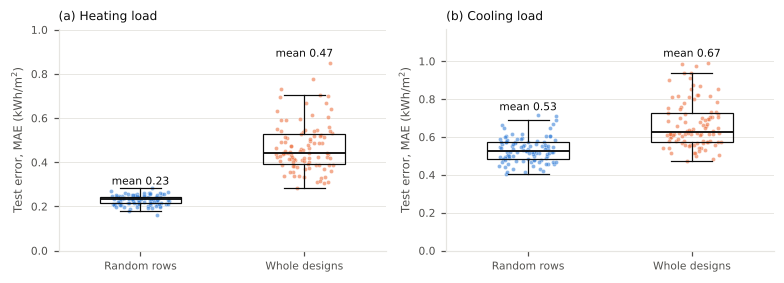

In [11]:
# Figure 4: the main result. Gradient Boosting error under the two ways of testing, 100 repeats each.
rng = np.random.default_rng(RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 2.6))
for ax, target, letter in zip(axes, TARGETS, ["(a)", "(b)"]):
    for i, (strategy, color) in enumerate([("Random rows", BLUE), ("Whole designs", ORANGE)]):
        v = rep[(rep.target == target) & (rep.model == "Gradient Boosting") & (rep.strategy == strategy)].MAE.values
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=7, color=color, alpha=0.55, edgecolor="white", linewidth=0.3, zorder=2)
        bp = ax.boxplot(v, positions=[i], widths=0.5, showfliers=False, patch_artist=True, zorder=3,
                        boxprops=dict(facecolor="none", edgecolor=INK, linewidth=0.8),
                        medianprops=dict(color=INK, linewidth=1.2), whiskerprops=dict(color=INK, linewidth=0.8),
                        capprops=dict(color=INK, linewidth=0.8))
        ax.text(i, v.max() + 0.02 * v.max(), f"mean {v.mean():.2f}", ha="center", va="bottom", fontsize=7, color=INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Random rows", "Whole designs"])
    ax.set_ylabel("Test error, MAE (kWh/m$^2$)"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, rep[(rep.target == target) & (rep.model == "Gradient Boosting")].MAE.max() * 1.18)
    ax.set_title(f"{letter} {LABEL[target]}")
fig.tight_layout(); save(fig, "fig4_gb_error_random_vs_whole_design"); plt.show()

**What this shows.** Over 100 repeated splits, the Gradient Boosting model's heating error rises from 0.23 to 0.47 kWh/m² when whole designs are held out, and it is higher in all 100 repeats. Cooling error rises from 0.53 to 0.67, higher in 81 of 100 repeats, with more overlap between the two boxes. The measured accuracy depends on how the test set is built.

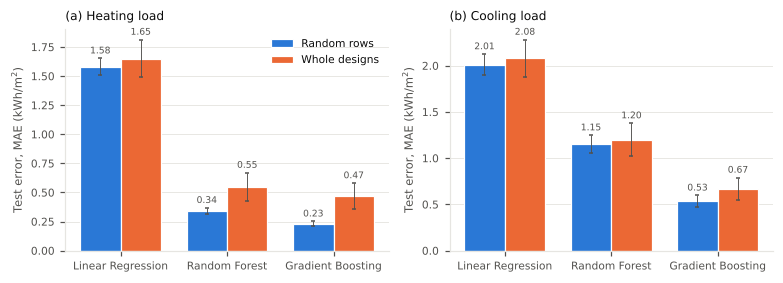

In [12]:
# Figure 5: the same comparison for all three models (mean over repeats, bars = 1 SD)
fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 2.6), sharey=False)
for ax, target, letter in zip(axes, TARGETS, ["(a)", "(b)"]):
    x = np.arange(len(MODELS)); w = 0.38
    for k, (strategy, color) in enumerate([("Random rows", BLUE), ("Whole designs", ORANGE)]):
        g = rep[(rep.target == target) & (rep.strategy == strategy)].groupby("model").MAE.agg(["mean", "std"]).loc[MODELS]
        bars = ax.bar(x + (k - 0.5) * w, g["mean"], w, yerr=g["std"], color=color, edgecolor="white", linewidth=0.8,
                      error_kw=dict(ecolor=INK_2, elinewidth=0.6, capsize=1.5), label=strategy)
        for b, v, sd in zip(bars, g["mean"], g["std"]):
            ax.text(b.get_x() + b.get_width() / 2, v + sd + 0.015 * g["mean"].max(), f"{v:.2f}", ha="center", va="bottom", fontsize=6, color=INK_2)
    ax.set_xticks(x); ax.set_xticklabels(MODELS); ax.grid(axis="x", visible=False)
    ax.set_ylabel("Test error, MAE (kWh/m$^2$)"); ax.set_title(f"{letter} {LABEL[target]}")
    if target == TARGETS[0]: ax.legend(loc="upper right")
fig.tight_layout(); save(fig, "fig5_all_models_random_vs_whole_design"); plt.show()

**What this shows.** The size of the change depends on the model. Linear Regression barely changes (about 4 to 5 percent), Random Forest changes by about 60 percent for heating but hardly at all for cooling, and Gradient Boosting changes the most (about 2 times for heating, 1.25 times for cooling). This pattern is consistent with more flexible models gaining more from seeing a test building's twins in training, though this study does not test that explanation directly.

## 6. One fixed whole-design split: predicted vs actual, and SHAP (paper Sections 5 and 6)
For the figures that need a single trained model, hold out 20% of the designs once (seed 42, the same split as the Update 3 notebook) and train Gradient Boosting on the rest.

In [13]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(splitter.split(df, groups=df["design_id"]))
train, test = df.iloc[tr_idx], df.iloc[te_idx]
assert set(train.design_id).isdisjoint(set(test.design_id))
print(f"Train: {train.design_id.nunique()} designs ({len(train)} rows) | Test: {test.design_id.nunique()} designs ({len(test)} rows)")

fixed_rows, fixed_models, fixed_preds = [], {}, {}
for target in TARGETS:
    for name in MODELS:
        pipe = make_pipeline(make_model(name, target)).fit(model_input(train), train[target])
        pred = pipe.predict(model_input(test)); fixed_preds[(target, name)] = pred
        fixed_rows.append({"Target": LABEL[target], "Model": name, **scores(test[target], pred)})
        if name == "Gradient Boosting": fixed_models[target] = pipe
table4 = pd.DataFrame(fixed_rows); display(table4.round(3)); save_table(table4.set_index(["Target", "Model"]), "table4_fixed_split_metrics")

Train: 153 designs (612 rows) | Test: 39 designs (156 rows)


,Target,Model,MAE,RMSE,R2
0,Heating load,Linear Regression,2.070,2.537,0.930
1,Heating load,Random Forest,0.581,0.956,0.990
2,Heating load,Gradient Boosting,0.541,1.101,0.987
3,Cooling load,Linear Regression,2.556,3.317,0.872
4,Cooling load,Random Forest,1.549,2.269,0.940
5,Cooling load,Gradient Boosting,0.815,1.220,0.983


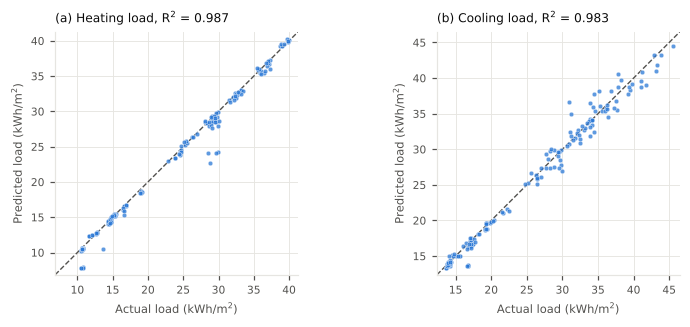

In [14]:
# Figure 6: predicted vs actual on the held-out designs
fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 3.0))
for ax, target, letter in zip(axes, TARGETS, ["(a)", "(b)"]):
    pred = fixed_preds[(target, "Gradient Boosting")]; y = test[target].values
    ax.scatter(y, pred, s=9, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.3, zorder=2)
    lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max()); pad = 0.03 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=INK_2, linestyle="--", linewidth=0.9, zorder=1)
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad); ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Actual load (kWh/m$^2$)"); ax.set_ylabel("Predicted load (kWh/m$^2$)")
    ax.set_title(f"{letter} {LABEL[target]}, R$^2$ = {r2_score(y, pred):.3f}")
fig.tight_layout(); save(fig, "fig6_predicted_vs_actual"); plt.show()

**What this shows.** On one fixed set of held-out designs, predictions stay close to the diagonal for both loads (R² = 0.987 for heating, 0.983 for cooling). A few heating predictions miss by several kWh/m², which is the kind of error a random split would have hidden.

ExactExplainer explainer:  51%|█████     | 79/156 [00:00<?, ?it/s]

ExactExplainer explainer:  52%|█████▏    | 81/156 [00:10<00:04, 17.01it/s]

ExactExplainer explainer:  53%|█████▎    | 83/156 [00:10<00:07,  9.84it/s]

ExactExplainer explainer:  54%|█████▍    | 85/156 [00:10<00:08,  8.80it/s]

ExactExplainer explainer:  55%|█████▌    | 86/156 [00:10<00:08,  8.60it/s]

ExactExplainer explainer:  56%|█████▌    | 87/156 [00:10<00:08,  8.06it/s]

... (147 outputs left out)

ExactExplainer explainer:  99%|█████████▉| 155/156 [00:20<00:00,  6.70it/s]

ExactExplainer explainer: 100%|██████████| 156/156 [00:20<00:00,  6.64it/s]

ExactExplainer explainer: 157it [00:21,  6.86it/s]                         

ExactExplainer explainer: 157it [00:21,  3.81it/s]

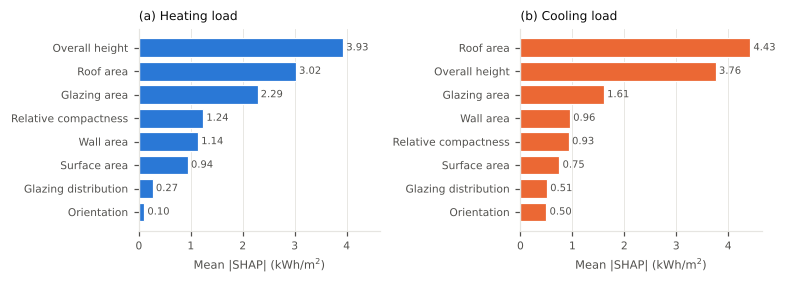

Target,Cooling_Load,Heating_Load
Feature,,
Overall_Height,3.76,3.93
Roof_Area,4.43,3.02
Glazing_Area,1.61,2.29
Relative_Compactness,0.93,1.24
Wall_Area,0.96,1.14
Surface_Area,0.75,0.94
Glazing_Area_Distribution,0.51,0.27
Orientation,0.50,0.10


In [15]:
# SHAP importance on the held-out designs, same exact method as the app
background = train[FEATURES].sample(100, random_state=RANDOM_STATE)
def explain(model, rows):
    f = lambda arr: model.predict(model_input(pd.DataFrame(arr, columns=FEATURES)))
    bg = background.sample(50, random_state=0)
    return shap.explainers.Exact(f, shap.maskers.Independent(bg, max_samples=50))(rows[FEATURES])

imp_rows = []
for target in TARGETS:
    sv = explain(fixed_models[target], test)
    for feat, val in zip(FEATURES, np.abs(sv.values).mean(axis=0)):
        imp_rows.append({"Target": target, "Feature": feat, "Mean_abs_SHAP": float(val)})
imp = pd.DataFrame(imp_rows)

fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 2.6), sharex=True)
for ax, target, color, letter in zip(axes, TARGETS, [BLUE, ORANGE], ["(a)", "(b)"]):
    sub = imp[imp.Target == target].sort_values("Mean_abs_SHAP")
    ax.barh([LABEL[f] for f in sub.Feature], sub.Mean_abs_SHAP, color=color, edgecolor="white", linewidth=0.8)
    for y, v in enumerate(sub.Mean_abs_SHAP):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=6.5, color=INK_2)
    ax.set_xlabel("Mean |SHAP| (kWh/m$^2$)"); ax.set_title(f"{letter} {LABEL[target]}"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "fig7_shap_importance"); plt.show()
shap_table = imp.pivot(index="Feature", columns="Target", values="Mean_abs_SHAP").sort_values("Heating_Load", ascending=False)
display(shap_table.round(2)); save_table(shap_table.round(3), "table5_shap_importance")

**What this shows.** For the model trained here, overall height and roof area lead for both loads, glazing area comes third, and orientation is last. Because height, roof, wall and surface area overlap (Figure 2), SHAP splits credit among them, so read them as one group describing the building's form. The order of the top two can change between model settings.

## 7. Numbers the paper quotes
These are the figures behind the main claims, so every number in the text can be traced to a table above.

In [16]:
gb = table3[(table3.Model == "Gradient Boosting")]
for target in ["Heating load", "Cooling load"]:
    for metric in ["MAE", "RMSE"]:
        r = gb[(gb.Target == target) & (gb.Metric == metric)].iloc[0]
        print(f"{target}, Gradient Boosting, {metric}: random rows {r['Random rows (mean)']:.3f} -> whole designs "
              f"{r['Whole designs (mean)']:.3f}  (x{r['Ratio (whole / random)']:.2f}); whole designs higher in "
              f"{r['Repeats where whole is higher']} repeats; paired difference 95% range {r['Diff 2.5%']:.3f} to {r['Diff 97.5%']:.3f}; "
              f"Wilcoxon p = {r['Wilcoxon p']:.2g}")
print()
print("Do all three models show it? (MAE ratio, whole designs / random rows)")
print(table3[table3.Metric == "MAE"][["Target", "Model", "Ratio (whole / random)", "Repeats where whole is higher"]].round(2).to_string(index=False))

Heating load, Gradient Boosting, MAE: random rows 0.229 -> whole designs 0.469  (x2.04); whole designs higher in 100 / 100 repeats; paired difference 95% range 0.081 to 0.490; Wilcoxon p = 3.9e-18
Heating load, Gradient Boosting, RMSE: random rows 0.347 -> whole designs 0.861  (x2.48); whole designs higher in 100 / 100 repeats; paired difference 95% range 0.077 to 1.239; Wilcoxon p = 3.9e-18
Cooling load, Gradient Boosting, MAE: random rows 0.532 -> whole designs 0.666  (x1.25); whole designs higher in 81 / 100 repeats; paired difference 95% range -0.091 to 0.455; Wilcoxon p = 8.8e-13
Cooling load, Gradient Boosting, RMSE: random rows 0.848 -> whole designs 0.951  (x1.12); whole designs higher in 65 / 100 repeats; paired difference 95% range -0.370 to 0.749; Wilcoxon p = 0.0003

Do all three models show it? (MAE ratio, whole designs / random rows)
      Target             Model  Ratio (whole / random) Repeats where whole is higher
Heating load Linear Regression                    1.05 

## 8. Zip the figures and tables

In [17]:
ZIP = "paper_figures_and_tables.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (FIG_DIR, TAB_DIR):
        for f in sorted(os.listdir(folder)):
            z.write(os.path.join(folder, f))
print("Wrote", ZIP, "with", len(zipfile.ZipFile(ZIP).namelist()), "files")
try:
    from google.colab import files
    files.download(ZIP)
except ImportError:
    pass

Wrote paper_figures_and_tables.zip with 21 files
